# Four-site eigenvalues and quadratic baseline

Evaluate Eq. (13) and the direct-diagonalization baseline for Fig. 5 and Sec. V D. The original primary calculation used interpolation over physical couplings; the independent verification used uniform ratios. This notebook explicitly uses the latter, so its metrics are not the original primary checkpoint's validation metrics.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from experiments.paper import ROOT
print('Repository:', ROOT)

Repository: /home/al/Documents/MNRKAN/NMRKan


In [2]:
from experiments.paper import exact_four, published_predictions, basis, make_dataset, metrics
config = json.loads((ROOT/'configs/paper/four_site_verification.json').read_text())
x,y,train,validation=make_dataset(config)
coeff=np.linalg.lstsq(basis(x)[train],y[train],rcond=None)[0]
pd.DataFrame({
    'OLS quadratic, validation': metrics(basis(x)[validation]@coeff,y[validation]),
    'Rounded Eq. (13), validation': metrics(published_predictions(x[validation]),y[validation]),
}).T[['rmse','max_abs_error']]

,rmse,max_abs_error
"OLS quadratic, validation",0.018227,0.074309
"Rounded Eq. (13), validation",0.041392,0.251


**Reproduction discrepancy:** the stated uniform-ratio protocol gives OLS RMSE about 0.01823, not the manuscript’s 0.00702. Rounded Eq. (13) gives about 0.04139 on this split. The physical-coupling sampling gives different errors (about 0.00683 for OLS). These protocols are kept separate; see the numerical discrepancy section of the reproduction guide. The original independent verification code/data are needed to resolve the mismatch.

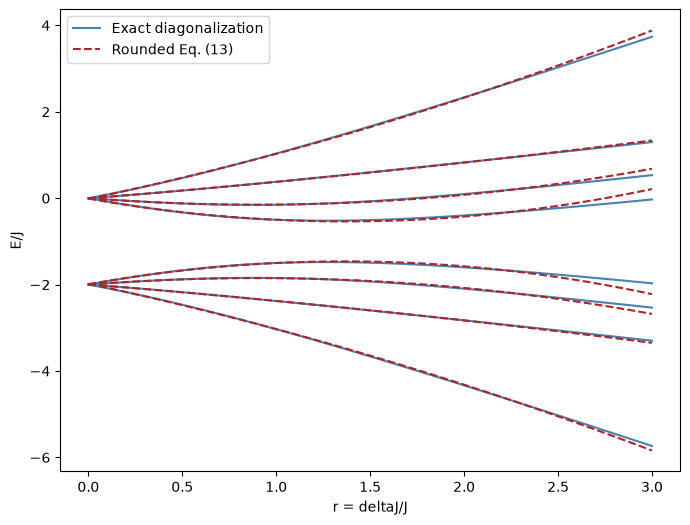

OLS coefficients: constant, linear, quadratic


,constant,linear,quadratic
1,-0.043509,1.000473,0.089914
2,-0.013213,0.374557,0.021760
3,-0.027577,-0.257042,0.153645
4,-0.057873,-0.631126,0.221799
5,-1.942127,0.631126,-0.221799
6,-1.972423,0.257042,-0.153645
7,-1.986787,-0.374557,-0.021760
8,-1.956491,-1.000473,-0.089914


In [3]:
r=np.linspace(0,3,601)[:,None]
exact=exact_four(r)
np.testing.assert_allclose(exact+exact[:,::-1],-2,atol=2e-14)
fig,ax=plt.subplots(figsize=(8,6))
ax.plot(r,exact,color='steelblue')
ax.plot(r,published_predictions(r),'--',color='firebrick')
ax.plot([],[],color='steelblue',label='Exact diagonalization')
ax.plot([],[],'--',color='firebrick',label='Rounded Eq. (13)')
ax.set(xlabel='r = deltaJ/J',ylabel='E/J');ax.legend()
plt.show()
print('OLS coefficients: constant, linear, quadratic')
display(pd.DataFrame(coeff.T,columns=['constant','linear','quadratic'],index=range(1,9)))

## Sampling and training protocols

```bash
# Primary: physical couplings sampled separately, 200x200 tracked interpolation grid.
python -m experiments.paper --config configs/paper/four_site.json --train
# Verification: direct diagonalization, uniform r in [0,3].
python -m experiments.paper --config configs/paper/four_site_verification.json --train
```
Both use `(1,10,8)`, 5000 epochs, Adam at 0.001, MSE and batch size 8000. Omit `--train` to evaluate the baselines and rounded formulas only. All configurations, datasets and split indices are saved. The supplied repository did not include the independently written historical verification implementation or its checkpoint; the new runner uses the shared repository ASN and labels its output as a fresh run.

## Completed full ASN runs for both sampling protocols

Both networks below were trained for all **5000 epochs on 10,000 samples**. The primary run samples physical couplings and uses the tracked interpolation grid. The verification run samples ratios uniformly and diagonalizes directly. These distributions must remain separate when interpreting errors.

four_site epochs: 5000 support: [[1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]


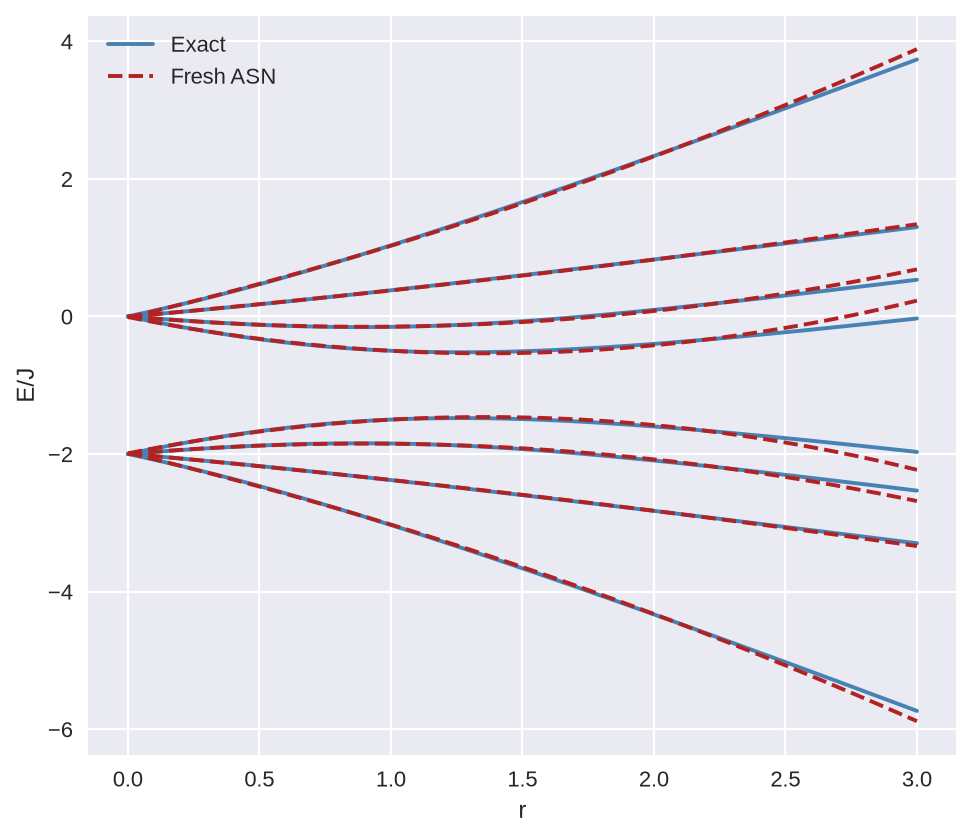

four_site_verification epochs: 5000 support: [[1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]


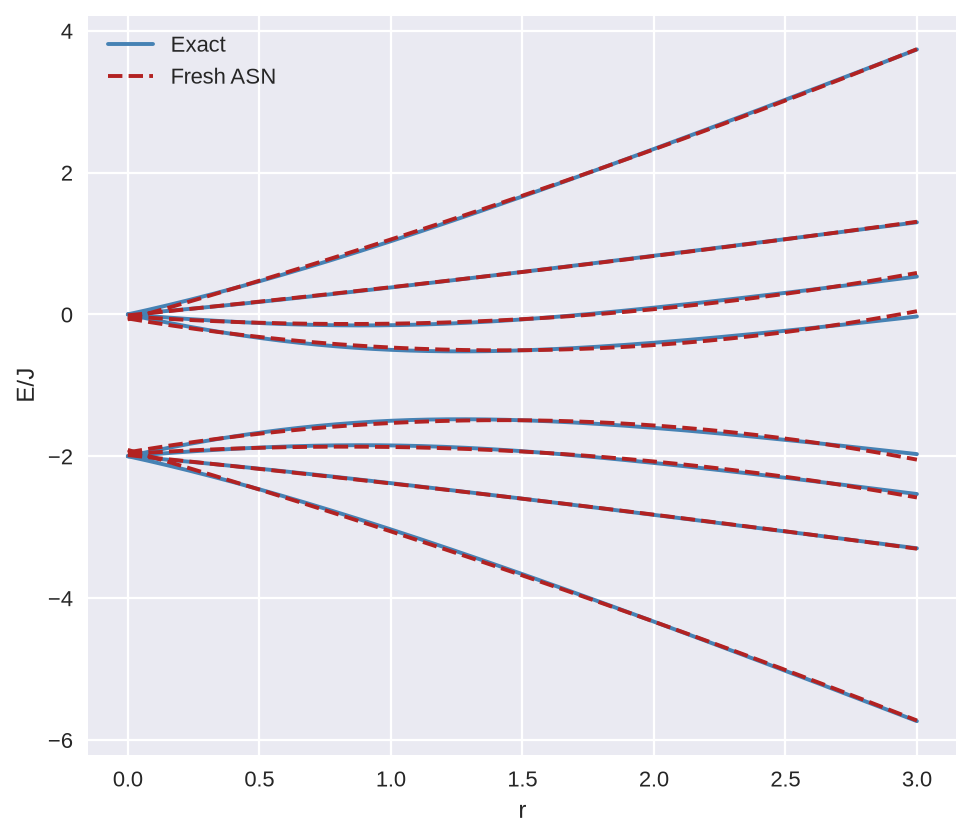

,protocol,paper_asn_rmse,rerun_asn_rmse,rerun_ols_rmse
0,four_site,0.00790,0.006834,0.006834
1,four_site_verification,0.00753,0.019916,0.018227


In [4]:
from experiments.reproduction import paper_run_root, load_run
from IPython.display import Image, display
rows=[]
for name,paper_rmse in [('four_site',.0079),('four_site_verification',.00753)]:
    folder=paper_run_root()/name
    trained=load_run(folder)
    rows.append(dict(protocol=name,paper_asn_rmse=paper_rmse,
                     rerun_asn_rmse=trained['validation_neural']['rmse'],
                     rerun_ols_rmse=trained['validation_ols']['rmse']))
    print(name,'epochs:',trained['config']['epochs'],'support:',trained['support_sizes'])
    display(Image(filename=str(folder/'fig05_branches.png')))
display(pd.DataFrame(rows))

The primary rerun gives approximately 0.00683 validation RMSE. Uniform-ratio verification gives approximately 0.01992 for the ASN and 0.01823 for OLS. Repeating full neural training therefore does not resolve the discrepancy with the paper's uniform-ratio numbers (0.00753 and 0.00702). All four protocol configurations, checkpoints, datasets, histories, and formulas are preserved in `results/reproduced/2026-11-08/paper/`.